In [1]:
# ========== Cell A: Mount Drive, upload/unzip dataset, prepare folders ==========
# Paste & run in Colab.

from google.colab import drive, files
import os, shutil, zipfile, glob, random
from pathlib import Path

# 1) Mount Google Drive
drive.mount('/content/drive', force_remount=True)

# 2) Create project folders in Drive
proj_root = Path("/content/drive/MyDrive/unet_project")
proj_root.mkdir(parents=True, exist_ok=True)
dataset_dir = proj_root / "dataset"
dataset_dir.mkdir(exist_ok=True)

print("Project root:", proj_root)
print("Dataset dir:", dataset_dir)

# 3) Upload the zip if not already present in Drive
# If you already placed 'archive (6).zip' in Drive -> skip upload
zipname = "archive.zip"
drive_zip_path = proj_root / zipname

if not drive_zip_path.exists():
    print("\n📤 Please upload your dataset zip now (archive (6).zip).")
    uploaded = files.upload()
    # Move uploaded file to Drive project folder
    for fname in uploaded.keys():
        print("Uploaded:", fname)
        # move to drive folder
        shutil.move(fname, str(drive_zip_path))
    print("Moved uploaded zip to:", drive_zip_path)
else:
    print("\nFound zip in Drive:", drive_zip_path)

# 4) Unzip into dataset folder (overwrite existing)
print("\nUnzipping to dataset folder (will overwrite existing files with same names)...")
with zipfile.ZipFile(str(drive_zip_path), 'r') as zf:
    zf.extractall(str(dataset_dir))
print("Unzipped. Contents preview (first 50 entries):")
for i, p in enumerate(sorted(glob.glob(str(dataset_dir / "**/*"), recursive=True))[:50]):
    print(i+1, p)

# 5) Find expected annotator folder and create images/masks targets
# Your original script used: "Annotator 1 (biologist)" -> "distance maps" and "mask binary"
annotator = dataset_dir / "Annotator 1 (biologist)"
src_images = annotator / "distance maps"
src_masks  = annotator / "mask binary"

if not src_images.exists() or not src_masks.exists():
    print("\n⚠️ Warning: Expected folders not found:")
    print("Looking for:\n ", src_images, "\n ", src_masks)
    print("Please verify the extracted folder structure and rerun this cell if necessary.")
else:
    # Create tidy images/masks folders at dataset root
    tgt_images = dataset_dir / "images"
    tgt_masks  = dataset_dir / "masks"
    tgt_images.mkdir(exist_ok=True)
    tgt_masks.mkdir(exist_ok=True)

    # Copy PNG files into images/ and masks/
    img_files = sorted(glob.glob(str(src_images / "*.png")))
    msk_files = sorted(glob.glob(str(src_masks / "*.png")))

    # Clear existing if any (careful)
    for f in glob.glob(str(tgt_images / "*.png")): os.remove(f)
    for f in glob.glob(str(tgt_masks / "*.png")): os.remove(f)

    for f in img_files:
        shutil.copy(f, tgt_images / Path(f).name)
    for f in msk_files:
        shutil.copy(f, tgt_masks / Path(f).name)

    print(f"\n✅ Copied {len(img_files)} images to {tgt_images}")
    print(f"✅ Copied {len(msk_files)} masks to {tgt_masks}")

    # 6) Create train/val split (80/20) and place them into images/train, images/val, masks/train, masks/val
    for d in ['images/train','images/val','masks/train','masks/val']:
        (dataset_dir / d).mkdir(parents=True, exist_ok=True)

    pairs = list(zip(sorted(glob.glob(str(tgt_images / "*.png"))), sorted(glob.glob(str(tgt_masks / "*.png")))))
    random.shuffle(pairs)
    split = int(0.8 * len(pairs))
    train_pairs, val_pairs = pairs[:split], pairs[split:]

    # Clear any previous train/val files
    for f in glob.glob(str(dataset_dir / "images/train/*")): os.remove(f)
    for f in glob.glob(str(dataset_dir / "images/val/*")): os.remove(f)
    for f in glob.glob(str(dataset_dir / "masks/train/*")): os.remove(f)
    for f in glob.glob(str(dataset_dir / "masks/val/*")): os.remove(f)

    for img, msk in train_pairs:
        shutil.copy(img, dataset_dir / "images/train" / os.path.basename(img))
        shutil.copy(msk, dataset_dir / "masks/train" / os.path.basename(msk))
    for img, msk in val_pairs:
        shutil.copy(img, dataset_dir / "images/val" / os.path.basename(img))
        shutil.copy(msk, dataset_dir / "masks/val" / os.path.basename(msk))

    print(f"✅ Split complete: {len(train_pairs)} train / {len(val_pairs)} val pairs.")
    print("\nTrain images example:", sorted(os.listdir(dataset_dir / "images/train"))[:5])
    print("Train masks example: ", sorted(os.listdir(dataset_dir / "masks/train"))[:5])
# ========== End Cell A ==========


Mounted at /content/drive
Project root: /content/drive/MyDrive/unet_project
Dataset dir: /content/drive/MyDrive/unet_project/dataset

📤 Please upload your dataset zip now (archive (6).zip).


Saving archive.zip to archive.zip
Uploaded: archive.zip
Moved uploaded zip to: /content/drive/MyDrive/unet_project/archive (6).zip

Unzipping to dataset folder (will overwrite existing files with same names)...
Unzipped. Contents preview (first 50 entries):
1 /content/drive/MyDrive/unet_project/dataset/Annotator 1 (biologist second round of manual marks up)
2 /content/drive/MyDrive/unet_project/dataset/Annotator 1 (biologist second round of manual marks up)/Annotator 1 (biologist second round of manual marks up)
3 /content/drive/MyDrive/unet_project/dataset/Annotator 1 (biologist second round of manual marks up)/Annotator 1 (biologist second round of manual marks up)/Imagj_zips
4 /content/drive/MyDrive/unet_project/dataset/Annotator 1 (biologist second round of manual marks up)/Annotator 1 (biologist second round of manual marks up)/Imagj_zips/Human_AdrenalGland_01_RoiSet
5 /content/drive/MyDrive/unet_project/dataset/Annotator 1 (biologist second round of manual marks up)/Annotator 1 (

In [2]:
# ========== Cell B: Train U-Net3+ (50 epochs) ==========
# Paste & run in Colab (after Cell A completes).
# GPU recommended.

!pip install albumentations==1.4.3 tqdm --quiet

import os, glob, random, shutil
from pathlib import Path
from glob import glob as gglob
import numpy as np
from PIL import Image
from tqdm import tqdm
import albumentations as A

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# ---------- Dataset ----------
class NucleiDataset(Dataset):
    def __init__(self, images_dir, masks_dir, transforms=None):
        self.images = sorted(glob.glob(os.path.join(images_dir, '*')))
        self.masks  = sorted(glob.glob(os.path.join(masks_dir, '*')))
        self.transforms = transforms
        assert len(self.images) == len(self.masks), "Images and masks count mismatch!"

    def __len__(self): return len(self.images)

    def __getitem__(self, idx):
        img = np.array(Image.open(self.images[idx]).convert('RGB'))
        mask = np.array(Image.open(self.masks[idx]).convert('L'))
        mask = (mask > 127).astype('uint8')
        if self.transforms:
            aug = self.transforms(image=img, mask=mask)
            img, mask = aug['image'], aug['mask']
        img = img.transpose(2,0,1).astype('float32') / 255.0
        mask = np.expand_dims(mask,0).astype('float32')
        return torch.tensor(img), torch.tensor(mask)

# ---------- Basic conv blocks ----------
class ConvBNRelu(nn.Module):
    def __init__(self, in_ch, out_ch, k=3, padding=1):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, k, padding=padding, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x): return self.conv(x)

class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            ConvBNRelu(in_ch, out_ch),
            ConvBNRelu(out_ch, out_ch)
        )
    def forward(self, x): return self.conv(x)

# ---------- U-Net3+ (compact) ----------
class UNet3Plus(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, base=32):
        super().__init__()
        nb = base
        self.enc1 = DoubleConv(in_ch, nb)
        self.pool = nn.MaxPool2d(2)
        self.enc2 = DoubleConv(nb, nb*2)
        self.enc3 = DoubleConv(nb*2, nb*4)
        self.enc4 = DoubleConv(nb*4, nb*8)
        self.enc5 = DoubleConv(nb*8, nb*16)

        self.n_filters = nb
        def _make_proj(in_c):
            return nn.Sequential(
                nn.Conv2d(in_c, self.n_filters, kernel_size=1, bias=False),
                nn.BatchNorm2d(self.n_filters),
                nn.ReLU(inplace=True)
            )
        self.proj_e1 = _make_proj(nb)
        self.proj_e2 = _make_proj(nb*2)
        self.proj_e3 = _make_proj(nb*4)
        self.proj_e4 = _make_proj(nb*8)
        self.proj_e5 = _make_proj(nb*16)

        concat_ch = self.n_filters * 5
        self.dec4 = DoubleConv(concat_ch, nb*8)
        self.dec3 = DoubleConv(concat_ch, nb*4)
        self.dec2 = DoubleConv(concat_ch, nb*2)
        self.dec1 = DoubleConv(concat_ch, nb)

        self.final = nn.Conv2d(nb, out_ch, kernel_size=1)

    def _resize_to(self, x, target_size):
        return nn.functional.interpolate(x, size=target_size, mode='bilinear', align_corners=True)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        e5 = self.enc5(self.pool(e4))

        s1, s2, s3, s4 = e1.shape[2:], e2.shape[2:], e3.shape[2:], e4.shape[2:]

        p1 = self.proj_e1(e1)
        p2 = self.proj_e2(e2)
        p3 = self.proj_e3(e3)
        p4 = self.proj_e4(e4)
        p5 = self.proj_e5(e5)

        a1_d4 = self._resize_to(p1, s4)
        a2_d4 = self._resize_to(p2, s4)
        a3_d4 = self._resize_to(p3, s4)
        a4_d4 = p4
        a5_d4 = self._resize_to(p5, s4)
        d4 = self.dec4(torch.cat([a1_d4, a2_d4, a3_d4, a4_d4, a5_d4], dim=1))

        a1_d3 = self._resize_to(p1, s3)
        a2_d3 = self._resize_to(p2, s3)
        a3_d3 = p3
        a4_d3 = self._resize_to(p4, s3)
        a5_d3 = self._resize_to(p5, s3)
        d3 = self.dec3(torch.cat([a1_d3, a2_d3, a3_d3, a4_d3, a5_d3], dim=1))

        a1_d2 = self._resize_to(p1, s2)
        a2_d2 = p2
        a3_d2 = self._resize_to(p3, s2)
        a4_d2 = self._resize_to(p4, s2)
        a5_d2 = self._resize_to(p5, s2)
        d2 = self.dec2(torch.cat([a1_d2, a2_d2, a3_d2, a4_d2, a5_d2], dim=1))

        a1_d1 = p1
        a2_d1 = self._resize_to(p2, s1)
        a3_d1 = self._resize_to(p3, s1)
        a4_d1 = self._resize_to(p4, s1)
        a5_d1 = self._resize_to(p5, s1)
        d1 = self.dec1(torch.cat([a1_d1, a2_d1, a3_d1, a4_d1, a5_d1], dim=1))

        out = self.final(d1)
        return out

# ---------- Loss ----------
def dice_loss(pred, target, eps=1e-6):
    pred = torch.sigmoid(pred)
    inter = (pred * target).sum()
    return 1 - (2*inter + eps) / (pred.sum() + target.sum() + eps)

# ---------- Training ----------
def train_model_unet3plus():
    dataset_dir = Path("/content/drive/MyDrive/unet_project/dataset")
    base_path = dataset_dir / "Annotator 1 (biologist)"

    train_tf = A.Compose([A.Resize(256,256), A.HorizontalFlip(p=0.5), A.VerticalFlip(p=0.5)])
    val_tf   = A.Compose([A.Resize(256,256)])

    img_path = base_path / "distance maps"
    mask_path = base_path / "mask binary"
    image_files = sorted(gglob(str(img_path / "*.png")))
    mask_files  = sorted(gglob(str(mask_path / "*.png")))
    pairs = list(zip(image_files, mask_files))
    random.shuffle(pairs)
    split = int(0.8 * len(pairs))
    train_pairs, val_pairs = pairs[:split], pairs[split:]

    os.makedirs("/content/train/images", exist_ok=True)
    os.makedirs("/content/train/masks", exist_ok=True)
    os.makedirs("/content/val/images", exist_ok=True)
    os.makedirs("/content/val/masks", exist_ok=True)

    for img, msk in train_pairs:
        shutil.copy(img, "/content/train/images/")
        shutil.copy(msk, "/content/train/masks/")
    for img, msk in val_pairs:
        shutil.copy(img, "/content/val/images/")
        shutil.copy(msk, "/content/val/masks/")

    train_ds = NucleiDataset("/content/train/images", "/content/train/masks", train_tf)
    val_ds   = NucleiDataset("/content/val/images", "/content/val/masks", val_tf)

    train_dl = DataLoader(train_ds, batch_size=4, shuffle=True, num_workers=2, pin_memory=True)
    val_dl   = DataLoader(val_ds, batch_size=4, num_workers=2)

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = UNet3Plus(in_ch=3, out_ch=1, base=32).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-4)
    best_dice = 0.0

    epochs = 50  # as requested
    for epoch in range(epochs):
        model.train()
        loss_sum = 0
        print(f"\n🔹 Epoch {epoch+1}/{epochs}")
        for img, mask in tqdm(train_dl, desc=f"Training {epoch+1}"):
            img, mask = img.to(device), mask.to(device)
            opt.zero_grad()
            out = model(img)
            loss = dice_loss(out, mask)
            loss.backward()
            opt.step()
            loss_sum += loss.item()
        print(f"Train loss: {loss_sum/len(train_dl):.4f}")

        # Validation
        model.eval()
        dice_total = 0
        with torch.no_grad():
            for img, mask in tqdm(val_dl, desc=f"Validating {epoch+1}"):
                img, mask = img.to(device), mask.to(device)
                out = model(img)
                dice = 1 - dice_loss(out, mask)
                dice_total += dice.item()
        avg_dice = dice_total / len(val_dl)
        print(f"Val Dice: {avg_dice:.4f}")

        if avg_dice > best_dice:
            best_dice = avg_dice
            torch.save(model.state_dict(), "/content/best_unet3plus.pth")
            print(f"✅ Saved best model locally with Dice: {best_dice:.4f}")

    # download final best
    from google.colab import files
    print("\n📥 Downloading trained model...")
    files.download("/content/best_unet3plus.pth")

# Run training
train_model_unet3plus()
# ========== End Cell B ==========


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.0/137.0 kB 3.5 MB/s eta 0:00:00

🔹 Epoch 1/50


Training 1:   0%|          | 0/6 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)
Training 1: 100%|██████████| 6/6 [00:50<00:00,  8.43s/it]


Train loss: 0.5616


Validating 1: 100%|██████████| 2/2 [00:04<00:00,  2.26s/it]


Val Dice: 0.3332
✅ Saved best model locally with Dice: 0.3332

🔹 Epoch 2/50


...

Train loss: 0.3436


Validating 50: 100%|██████████| 2/2 [00:05<00:00,  2.87s/it]

Val Dice: 0.6655
✅ Saved best model locally with Dice: 0.6655

📥 Downloading trained model...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

📂 Upload your trained U-Net3+ model (.pth):


Saving best_unet3plus.pth to best_unet3plus (2).pth
✅ Model uploaded: best_unet3plus (2).pth
✅ Model loaded successfully!

🖼️ Upload a .tif or .png test image:


Saving Human_AdrenalGland_01.png to Human_AdrenalGland_01.png
✅ Using: Human_AdrenalGland_01.png
✅ Saved: pred_mask_256_unet3plus.png and pred_mask_original_size_unet3plus.png

📁 Upload ground truth mask (same image) to compute metrics:


Saving Human_AdrenalGland_01.png to Human_AdrenalGland_01 (1).png

📊 Evaluation Metrics (Resized to 256x256):
   • Mean IoU  : 0.9166
   • Dice (F1) : 0.9565


/tmp/ipython-input-1992630979.py:189: UserWarning: Glyph 129656 (\N{DROP OF BLOOD}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipython-input-1992630979.py:189: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipython-input-1992630979.py:189: UserWarning: Glyph 129504 (\N{BRAIN}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 129656 (\N{DROP OF BLOOD}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 129504 (\N{BRAIN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(byt

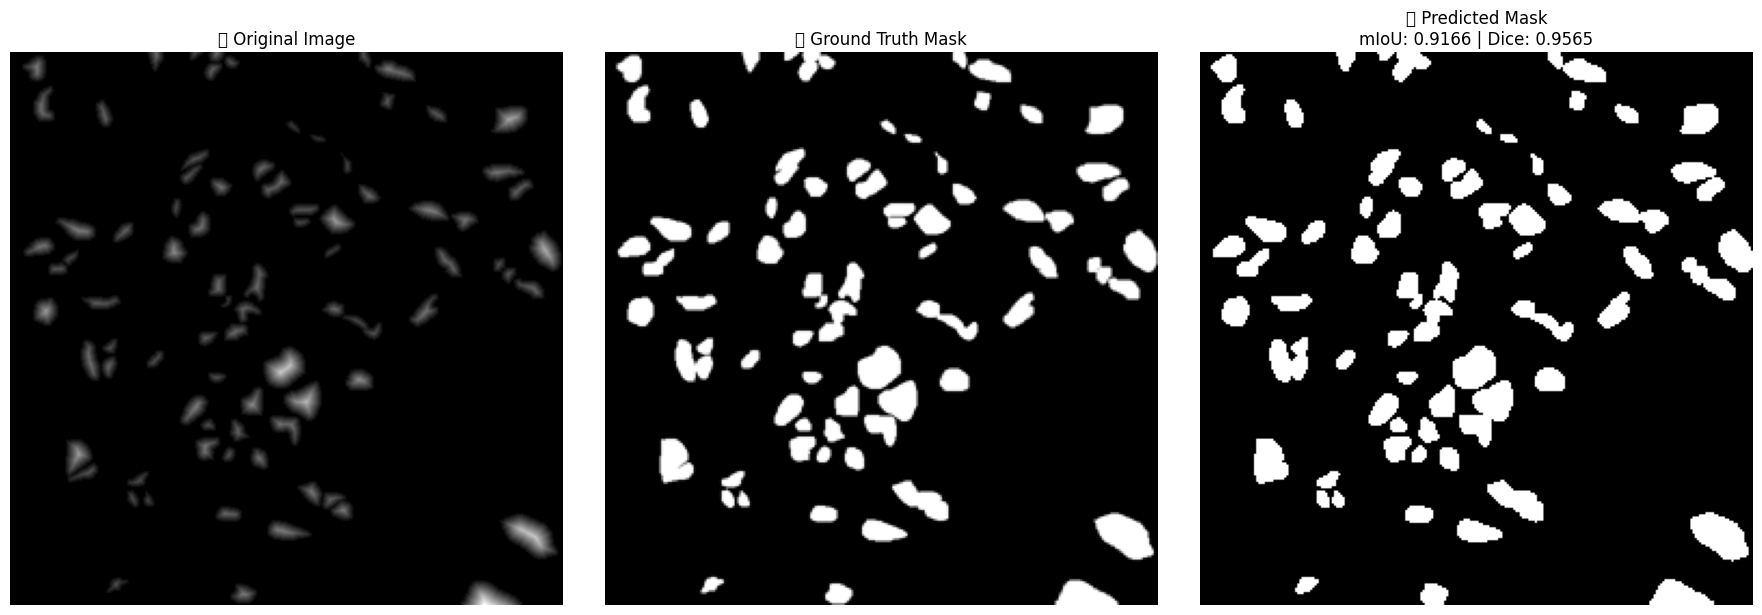

In [6]:
# ========== Cell C: Inference - upload model, test image, GT mask ==========
# Paste & run in Colab (after training or at any time).
# Upload your .pth model file when prompted, plus a test image and its GT mask.

from google.colab import files
import torch, numpy as np, cv2
from PIL import Image
import matplotlib.pyplot as plt
import torch.nn as nn

# Re-declare model architecture (must match training)
class ConvBNRelu(nn.Module):
    def __init__(self, in_ch, out_ch, k=3, padding=1):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, k, padding=padding, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x): return self.conv(x)

class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            ConvBNRelu(in_ch, out_ch),
            ConvBNRelu(out_ch, out_ch)
        )
    def forward(self, x): return self.conv(x)

class UNet3Plus(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, base=32):
        super().__init__()
        nb = base
        self.enc1 = DoubleConv(in_ch, nb)
        self.pool = nn.MaxPool2d(2)
        self.enc2 = DoubleConv(nb, nb*2)
        self.enc3 = DoubleConv(nb*2, nb*4)
        self.enc4 = DoubleConv(nb*4, nb*8)
        self.enc5 = DoubleConv(nb*8, nb*16)

        self.n_filters = nb
        def _make_proj(in_c):
            return nn.Sequential(
                nn.Conv2d(in_c, self.n_filters, kernel_size=1, bias=False),
                nn.BatchNorm2d(self.n_filters),
                nn.ReLU(inplace=True)
            )
        self.proj_e1 = _make_proj(nb)
        self.proj_e2 = _make_proj(nb*2)
        self.proj_e3 = _make_proj(nb*4)
        self.proj_e4 = _make_proj(nb*8)
        self.proj_e5 = _make_proj(nb*16)

        concat_ch = self.n_filters * 5
        self.dec4 = DoubleConv(concat_ch, nb*8)
        self.dec3 = DoubleConv(concat_ch, nb*4)
        self.dec2 = DoubleConv(concat_ch, nb*2)
        self.dec1 = DoubleConv(concat_ch, nb)

        self.final = nn.Conv2d(nb, out_ch, kernel_size=1)

    def _resize_to(self, x, target_size):
        return nn.functional.interpolate(x, size=target_size, mode='bilinear', align_corners=True)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        e5 = self.enc5(self.pool(e4))

        s1, s2, s3, s4 = e1.shape[2:], e2.shape[2:], e3.shape[2:], e4.shape[2:]

        p1 = self.proj_e1(e1)
        p2 = self.proj_e2(e2)
        p3 = self.proj_e3(e3)
        p4 = self.proj_e4(e4)
        p5 = self.proj_e5(e5)

        a1_d4 = self._resize_to(p1, s4)
        a2_d4 = self._resize_to(p2, s4)
        a3_d4 = self._resize_to(p3, s4)
        a4_d4 = p4
        a5_d4 = self._resize_to(p5, s4)
        d4 = self.dec4(torch.cat([a1_d4, a2_d4, a3_d4, a4_d4, a5_d4], dim=1))

        a1_d3 = self._resize_to(p1, s3)
        a2_d3 = self._resize_to(p2, s3)
        a3_d3 = p3
        a4_d3 = self._resize_to(p4, s3)
        a5_d3 = self._resize_to(p5, s3)
        d3 = self.dec3(torch.cat([a1_d3, a2_d3, a3_d3, a4_d3, a5_d3], dim=1))

        a1_d2 = self._resize_to(p1, s2)
        a2_d2 = p2
        a3_d2 = self._resize_to(p3, s2)
        a4_d2 = self._resize_to(p4, s2)
        a5_d2 = self._resize_to(p5, s2)
        d2 = self.dec2(torch.cat([a1_d2, a2_d2, a3_d2, a4_d2, a5_d2], dim=1))

        a1_d1 = p1
        a2_d1 = self._resize_to(p2, s1)
        a3_d1 = self._resize_to(p3, s1)
        a4_d1 = self._resize_to(p4, s1)
        a5_d1 = self._resize_to(p5, s1)
        d1 = self.dec1(torch.cat([a1_d1, a2_d1, a3_d1, a4_d1, a5_d1], dim=1))

        out = self.final(d1)
        return out

# ---- Upload trained model (.pth) ----
print("📂 Upload your trained U-Net3+ model (.pth):")
uploaded_model = files.upload()
model_path = list(uploaded_model.keys())[0]
print(f"✅ Model uploaded: {model_path}")

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = UNet3Plus(in_ch=3, out_ch=1, base=32)
model.load_state_dict(torch.load(model_path, map_location=device))
model.to(device).eval()
print("✅ Model loaded successfully!")

# ---- Upload test image ----
print("\n🖼️ Upload a .tif or .png test image:")
uploaded_img = files.upload()
img_path = list(uploaded_img.keys())[0]
print(f"✅ Using: {img_path}")

img_orig = Image.open(img_path).convert('RGB')
orig_w, orig_h = img_orig.size

img_resized = img_orig.resize((256,256))
img_np = np.array(img_resized).astype('float32') / 255.0
img_tensor = torch.tensor(img_np.transpose(2,0,1)).unsqueeze(0).to(device)

# ---- Predict ----
with torch.no_grad():
    pred = model(img_tensor)
mask = torch.sigmoid(pred)[0,0].cpu().numpy()

# ---- Convert to binary mask and save ----
mask_bin_256 = (mask > 0.5).astype(np.uint8) * 255
mask_bin_orig = cv2.resize(mask_bin_256, (orig_w, orig_h), interpolation=cv2.INTER_NEAREST)

cv2.imwrite("pred_mask_256_unet3plus.png", mask_bin_256)
cv2.imwrite("pred_mask_original_size_unet3plus.png", mask_bin_orig)
print("✅ Saved: pred_mask_256_unet3plus.png and pred_mask_original_size_unet3plus.png")

# ---- Upload GT mask for metrics ----
print("\n📁 Upload ground truth mask (same image) to compute metrics:")
uploaded_gt = files.upload()
gt_path = list(uploaded_gt.keys())[0]
gt_mask = Image.open(gt_path).convert('L')
gt_mask_resized = gt_mask.resize((256,256))
gt_np = np.array(gt_mask_resized).astype('float32') / 255.0

# ---- Metric functions ----
def iou_pytorch(preds, labels, smooth=1e-6):
    preds = torch.tensor(preds).unsqueeze(0)
    labels = torch.tensor(labels).unsqueeze(0)
    preds = (preds > 0.5).float()
    labels = (labels > 0.5).float()
    intersection = (preds * labels).sum()
    union = preds.sum() + labels.sum() - intersection
    return ((intersection + smooth) / (union + smooth)).item()

def dice_pytorch(preds, labels, smooth=1e-6):
    preds = torch.tensor(preds).unsqueeze(0)
    labels = torch.tensor(labels).unsqueeze(0)
    preds = (preds > 0.5).float()
    labels = (labels > 0.5).float()
    intersection = (preds * labels).sum()
    return ((2 * intersection + smooth) / (preds.sum() + labels.sum() + smooth)).item()

mIoU = iou_pytorch(mask, gt_np)
dice = dice_pytorch(mask, gt_np)

print(f"\n📊 Evaluation Metrics (Resized to 256x256):")
print(f"   • Mean IoU  : {mIoU:.4f}")
print(f"   • Dice (F1) : {dice:.4f}")

# ---- Display results ----
plt.figure(figsize=(18,6))
plt.subplot(1,3,1); plt.imshow(img_orig); plt.title("🩸 Original Image"); plt.axis('off')
plt.subplot(1,3,2); plt.imshow(gt_np, cmap='gray'); plt.title("🎯 Ground Truth Mask"); plt.axis('off')
plt.subplot(1,3,3); plt.imshow(mask_bin_256, cmap='gray')
plt.title(f"🧠 Predicted Mask\nmIoU: {mIoU:.4f} | Dice: {dice:.4f}"); plt.axis('off')
plt.tight_layout(); plt.show()
# ========== End Cell C ==========


In [5]:
# List first 20 test images from the "distance maps" folder
!ls "/content/drive/MyDrive/unet_project/dataset/Annotator 1 (biologist)/distance maps" | head -n 20

# List first 20 ground truth masks from the "mask binary" folder
!ls "/content/drive/MyDrive/unet_project/dataset/Annotator 1 (biologist)/mask binary" | head -n 20


Human_AdrenalGland_01.png
Human_AdrenalGland_02.png
Human_AdrenalGland_03.png
Human_Larynx_01.png
Human_Larynx_02.png
Human_Larynx_03.png
Human_LymphNodes_01.png
Human_LymphNodes_02.png
Human_LymphNodes_03.png
Human_Mediastinum_01.png
Human_Mediastinum_02.png
Human_Mediastinum_03.png
Human_Pancreas_01.png
Human_Pancreas_02.png
Human_Pancreas_03.png
Human_Pleura_01.png
Human_Pleura_02.png
Human_Pleura_03.png
Human_Skin_01.png
Human_Skin_02.png
Human_AdrenalGland_01.png
Human_AdrenalGland_02.png
Human_AdrenalGland_03.png
Human_Larynx_01.png
Human_Larynx_02.png
Human_Larynx_03.png
Human_LymphNodes_01.png
Human_LymphNodes_02.png
Human_LymphNodes_03.png
Human_Mediastinum_01.png
Human_Mediastinum_02.png
Human_Mediastinum_03.png
Human_Pancreas_01.png
Human_Pancreas_02.png
Human_Pancreas_03.png
Human_Pleura_01.png
Human_Pleura_02.png
Human_Pleura_03.png
Human_Skin_01.png
Human_Skin_02.png


pred_mask_256_unet3plus.png exists? True
pred_mask_original_size_unet3plus.png exists? True
Human_AdrenalGland_01 (1).png exists? True
Human_AdrenalGland_01.png exists? True

Metrics (on 256x256):
  mIoU : 0.9166
  Dice : 0.9565
  Prec : 0.9166
  Rec  : 1.0000
  TP/FP/FN : 7901/719/0


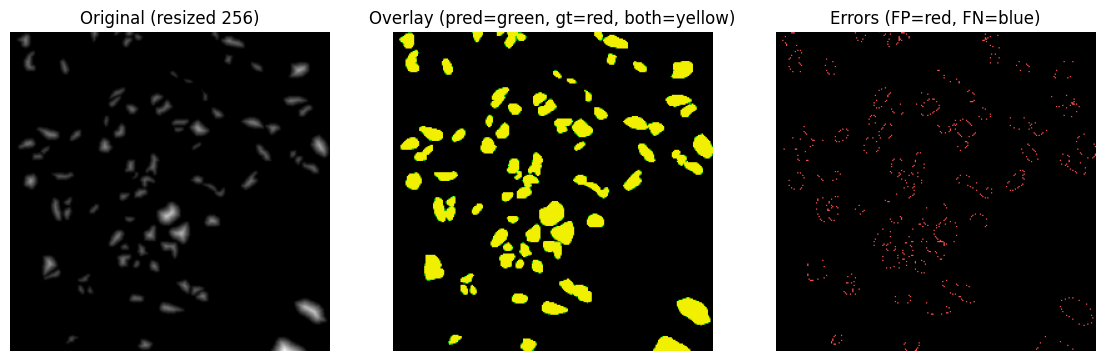


Metrics (original-size): mIoU 0.8895 | Dice 0.9415


In [8]:
# Corrected diagnostics — set GT_FILENAME exactly to the file printed in your inference cell
import numpy as np, cv2, matplotlib.pyplot as plt
from PIL import Image
import os

# Files saved by the inference cell
PRED256 = "pred_mask_256_unet3plus.png"
PRED_ORIG = "pred_mask_original_size_unet3plus.png"

# <-- set this to the exact GT file name that appeared in your inference output:
GT_FILENAME = "Human_AdrenalGland_01 (1).png"   # <- probably this; change if different

# Also set the original test image name if needed
TEST_IMG = "Human_AdrenalGland_01.png"

# sanity checks
for f in [PRED256, PRED_ORIG, GT_FILENAME, TEST_IMG]:
    print(f, "exists?", os.path.exists(f))

# Load predicted (256) and GT (resize to 256 to match prediction metrics)
pred = np.array(Image.open(PRED256).convert('L')) > 127
gt_256 = np.array(Image.open(GT_FILENAME).convert('L').resize(pred.shape[::-1])) > 127

# Basic metrics functions
def iou_np(pred, gt, eps=1e-6):
    inter = np.logical_and(pred, gt).sum()
    union = np.logical_or(pred, gt).sum()
    return (inter + eps) / (union + eps)

def dice_np(pred, gt, eps=1e-6):
    inter = np.logical_and(pred, gt).sum()
    return (2*inter + eps) / (pred.sum() + gt.sum() + eps)

def precision_recall(pred, gt, eps=1e-6):
    tp = np.logical_and(pred, gt).sum()
    fp = np.logical_and(pred, ~gt).sum()
    fn = np.logical_and(~pred, gt).sum()
    prec = (tp + eps) / (tp + fp + eps)
    rec  = (tp + eps) / (tp + fn + eps)
    return prec, rec, tp, fp, fn

miou = iou_np(pred, gt_256)
dice = dice_np(pred, gt_256)
prec, rec, tp, fp, fn = precision_recall(pred, gt_256)

print("\nMetrics (on 256x256):")
print(f"  mIoU : {miou:.4f}")
print(f"  Dice : {dice:.4f}")
print(f"  Prec : {prec:.4f}")
print(f"  Rec  : {rec:.4f}")
print(f"  TP/FP/FN : {tp}/{fp}/{fn}")

# Visual overlays (256)
orig_resized = np.array(Image.open(TEST_IMG).convert('RGB').resize(pred.shape[::-1]))
overlay = orig_resized.copy()
overlay[pred]  = (0,180,0)   # predicted -> green
overlay[gt_256] = (180,0,0)  # gt -> red
both = np.logical_and(pred, gt_256)
overlay[both] = (240,240,0)  # both -> yellow

fp_mask = np.logical_and(pred, ~gt_256)
fn_mask = np.logical_and(~pred, gt_256)
diff = np.zeros((pred.shape[0], pred.shape[1],3), dtype=np.uint8)
diff[fp_mask] = [255,80,80]
diff[fn_mask] = [80,80,255]

plt.figure(figsize=(14,6))
plt.subplot(1,3,1); plt.imshow(orig_resized); plt.title("Original (resized 256)"); plt.axis('off')
plt.subplot(1,3,2); plt.imshow(overlay); plt.title("Overlay (pred=green, gt=red, both=yellow)"); plt.axis('off')
plt.subplot(1,3,3); plt.imshow(diff); plt.title("Errors (FP=red, FN=blue)"); plt.axis('off')
plt.show()

# Also compute metrics on original size (optional)
if os.path.exists(PRED_ORIG):
    pred_orig = np.array(Image.open(PRED_ORIG).convert('L')) > 127
    gt_orig = np.array(Image.open(GT_FILENAME).convert('L'))
    # resize GT to original pred size if necessary
    if gt_orig.shape != pred_orig.shape:
        gt_orig = np.array(Image.open(GT_FILENAME).convert('L').resize((pred_orig.shape[1], pred_orig.shape[0]))) > 127
    else:
        gt_orig = gt_orig > 127
    miou_o = iou_np(pred_orig, gt_orig)
    dice_o = dice_np(pred_orig, gt_orig)
    print(f"\nMetrics (original-size): mIoU {miou_o:.4f} | Dice {dice_o:.4f}")
else:
    print("\nOriginal-size predicted mask not found; skipping original-size metrics.")


In [9]:
# Run in Colab — compute mIoU/Dice/Prec/Recall on original-size saved files
import numpy as np
from PIL import Image
import os

pred_orig = np.array(Image.open("pred_mask_original_size_unet3plus.png").convert('L')) > 127
gt_orig   = np.array(Image.open("Human_AdrenalGland_01 (1).png").convert('L')) > 127

def iou_np(p,g,eps=1e-6):
    inter = np.logical_and(p,g).sum()
    union = np.logical_or(p,g).sum()
    return (inter+eps)/(union+eps)

def dice_np(p,g,eps=1e-6):
    inter = np.logical_and(p,g).sum()
    return (2*inter+eps)/(p.sum()+g.sum()+eps)

def prec_rec(p,g,eps=1e-6):
    tp = np.logical_and(p,g).sum()
    fp = np.logical_and(p,~g).sum()
    fn = np.logical_and(~p,g).sum()
    return (tp+eps)/(tp+fp+eps), (tp+eps)/(tp+fn+eps), tp, fp, fn

miou_o = iou_np(pred_orig, gt_orig)
dice_o = dice_np(pred_orig, gt_orig)
prec_o, rec_o, tp, fp, fn = prec_rec(pred_orig, gt_orig)

print(f"Original-size metrics: mIoU {miou_o:.4f} | Dice {dice_o:.4f} | Prec {prec_o:.4f} | Rec {rec_o:.4f}")
print("TP/FP/FN:", tp, fp, fn)


Original-size metrics: mIoU 0.8895 | Dice 0.9415 | Prec 0.8943 | Rec 0.9940
TP/FP/FN: 30835 3645 186


In [10]:
# Paste & run in Colab (assumes dataset split is at /content/drive/MyDrive/unet_project/dataset/)
import torch, numpy as np
from PIL import Image
import glob, os
from tqdm import tqdm

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# re-declare model if needed, or load the same way you did previously
# Below assume UNet3Plus definition is in memory; if not re-run the model class cell and load weights

model = UNet3Plus(in_ch=3, out_ch=1, base=32)
model.load_state_dict(torch.load("best_unet3plus.pth", map_location=device))
model.to(device).eval()

val_imgs = sorted(glob.glob("/content/drive/MyDrive/unet_project/dataset/images/val/*.png"))
val_masks = sorted(glob.glob("/content/drive/MyDrive/unet_project/dataset/masks/val/*.png"))
assert len(val_imgs)==len(val_masks)

def compute_metrics(pred_mask, gt_mask):
    p = pred_mask>0.5
    g = gt_mask>0.5
    inter = (p & g).sum()
    union = (p | g).sum()
    iou = (inter+1e-6)/(union+1e-6)
    dice = (2*inter+1e-6)/(p.sum()+g.sum()+1e-6)
    tp = (p & g).sum()
    fp = (p & ~g).sum()
    fn = (~p & g).sum()
    prec = (tp+1e-6)/(tp+fp+1e-6)
    rec  = (tp+1e-6)/(tp+fn+1e-6)
    return iou, dice, prec, rec

all_iou, all_dice, all_prec, all_rec = [], [], [], []
for img_path, gt_path in tqdm(zip(val_imgs, val_masks), total=len(val_imgs)):
    img = Image.open(img_path).convert('RGB').resize((256,256))
    img_np = np.array(img).astype('float32')/255.0
    t = torch.tensor(img_np.transpose(2,0,1)).unsqueeze(0).to(device)
    with torch.no_grad():
        out = model(t)
        pred = torch.sigmoid(out)[0,0].cpu().numpy()
    gt = np.array(Image.open(gt_path).convert('L').resize((256,256))).astype('float32')/255.0
    iou,dice,prec,rec = compute_metrics(pred, gt)
    all_iou.append(iou); all_dice.append(dice); all_prec.append(prec); all_rec.append(rec)

print("Val set averages:")
print(" mIoU:", np.mean(all_iou), " Dice:", np.mean(all_dice))
print(" Prec:", np.mean(all_prec), " Rec:", np.mean(all_rec))


100%|██████████| 6/6 [00:03<00:00,  1.61it/s]

Val set averages:
 mIoU: 0.8919981271508698  Dice: 0.9427730366661894
 Prec: 0.8922207919334446  Rec: 0.9997322354985899


In [11]:
# from Colab, move final file to Drive
import shutil
shutil.copy("best_unet3plus.pth", "/content/drive/MyDrive/unet_project/best_unet3plus.pth")
print("Saved to Drive: /content/drive/MyDrive/unet_project/best_unet3plus.pth")


Saved to Drive: /content/drive/MyDrive/unet_project/best_unet3plus.pth
